# Energy & Weather Data Cleaning, EDA & Time-Based Split
**Key Pipeline Techniques:**
- **Reproducible Setup:** `pathlib.Path`, `@dataclass` config, type hints, `@timed` decorator, and `assert` checks
- **Numerical & Plotting Discipline:** Explicit `float32` dtype, vectorized broadcasting standardization `(X - mu) / sd`, and `fig, ax = plt.subplots()`
- **Efficient Storage:** Columnar Parquet storage (`.to_parquet()`, `read_parquet(columns=...)`) and contiguous `float32` arrays (`np.ascontiguousarray`)
- **Tabular Processing:** `.info()`, `.describe()`, `.isna().sum()`, `.loc[mask, col]`, `.str` / `.dt` / `category` dtype, `groupby` (`agg` vs `transform`), merge assertions (`is_unique`, `how='left'`, `validate=`, row-count `assert`), and a 4-panel Seaborn EDA figure (`histplot`, `scatterplot`, `boxplot`, `heatmap`)

In [11]:
from dataclasses import dataclass
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
rng = np.random.default_rng(0)  # Local reproducible RNG

@dataclass
class PipelineConfig:
    """Configuration for paths and chronological split ratios."""
    root_dir: Path = Path('..') if Path('../data').exists() else Path('.')
    data_dir: Path = root_dir / 'data'
    out_dir: Path = root_dir / 'data/splits'
    plot_dir: Path = root_dir / 'plots'
    train_ratio: float = 0.70
    val_ratio: float = 0.15

cfg = PipelineConfig()
cfg.out_dir.mkdir(parents=True, exist_ok=True)
cfg.plot_dir.mkdir(parents=True, exist_ok=True)

def timed(fn):
    """Decorator to measure execution time of pipeline steps."""
    def wrapper(*args, **kwargs):
        t0 = time.perf_counter()
        out = fn(*args, **kwargs)
        print(f"{fn.__name__}: {time.perf_counter() - t0:.4f}s")
        return out
    return wrapper

## Step 1: Inspect Raw Data Before Computing
- Check `.shape`, `.head()`, `.dtypes`, `.info()`, `.describe()`
- Count missing values first (`.isna().sum()`), because aggregations silently skip `NaN`.

In [12]:
energy_raw = pd.read_csv(cfg.data_dir / 'energy_dataset.csv')
weather_raw = pd.read_csv(cfg.data_dir / 'weather_features.csv')

print('Energy shape:', energy_raw.shape)
print('Weather shape:', weather_raw.shape)
energy_raw.info()

Energy shape: (35064, 29)
Weather shape: (178396, 17)
<class 'pandas.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 29 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   time                                         35064 non-null  str    
 1   generation biomass                           35045 non-null  float64
 2   generation fossil brown coal/lignite         35046 non-null  float64
 3   generation fossil coal-derived gas           35046 non-null  float64
 4   generation fossil gas                        35046 non-null  float64
 5   generation fossil hard coal                  35046 non-null  float64
 6   generation fossil oil                        35045 non-null  float64
 7   generation fossil oil shale                  35046 non-null  float64
 8   generation fossil peat                       35046 non-null  float64
 9   generation geothermal        

In [13]:
# Count NaNs and inspect summary statistics
print('--- Energy Missing Counts ---')
print(energy_raw.isna().sum()[lambda s: s > 0])

print('\n--- Energy All-Zero Columns ---')
print((energy_raw == 0).sum()[lambda s: s > 34000])

print('\n--- Weather Summary (spot pressure & wind_speed outliers!) ---')
weather_raw[['temp', 'pressure', 'humidity', 'wind_speed']].describe()

--- Energy Missing Counts ---
generation biomass                                19
generation fossil brown coal/lignite              18
generation fossil coal-derived gas                18
generation fossil gas                             18
generation fossil hard coal                       18
generation fossil oil                             19
generation fossil oil shale                       18
generation fossil peat                            18
generation geothermal                             18
generation hydro pumped storage aggregated     35064
generation hydro pumped storage consumption       19
generation hydro run-of-river and poundage        19
generation hydro water reservoir                  18
generation marine                                 19
generation nuclear                                17
generation other                                  18
generation other renewable                        18
generation solar                                  18
generation waste

,temp,pressure,humidity,wind_speed
count,178396.000000,1.783960e+05,178396.000000,178396.00000
mean,289.618605,1.069261e+03,68.423457,2.47056
std,8.026199,5.969632e+03,21.902888,2.09591
min,262.240000,0.000000e+00,0.000000,0.00000
25%,283.670000,1.013000e+03,53.000000,1.00000
50%,289.150000,1.018000e+03,72.000000,2.00000
75%,295.150000,1.022000e+03,87.000000,4.00000
max,315.600000,1.008371e+06,100.000000,133.00000


## Step 2: Clean `energy_dataset.csv`
- Parse `time` to UTC datetime (`pd.to_datetime(..., utc=True)`)
- Drop 2 completely `NaN` columns and 6 all-zero columns
- Derive time features using vectorized `.dt` accessor (`.dt.hour`, `.dt.month`, `.dt.day_of_week`)
- Repair brief 17–36 hour sensor gaps with `.ffill().bfill()` and `assert` shape & zero NaNs

In [14]:
@timed
def clean_energy(df: pd.DataFrame) -> pd.DataFrame:
    before_rows = len(df)
    drop_cols = [
        # 100% NaN columns
        'generation hydro pumped storage aggregated',
        'forecast wind offshore eday ahead',
        # All-zero columns
        'generation fossil coal-derived gas',
        'generation fossil oil shale',
        'generation fossil peat',
        'generation geothermal',
        'generation marine',
        'generation wind offshore',
    ]
    out = (
        df.drop(columns=drop_cols)
        .assign(time=lambda d: pd.to_datetime(d['time'], utc=True))
        .sort_values('time')
        .reset_index(drop=True)
        .ffill()
        .bfill()
        .assign(
            hour=lambda d: d['time'].dt.hour,
            month=lambda d: d['time'].dt.month,
            dayofweek=lambda d: d['time'].dt.dayofweek,
        )
    )
    assert len(out) == before_rows, f"Row count changed: {before_rows} -> {len(out)}"
    assert out['time'].is_unique, "Energy timestamps must be unique!"
    assert out.isna().sum().sum() == 0, "NaNs remain in cleaned energy table!"
    return out

energy = clean_energy(energy_raw)
print('Cleaned energy shape:', energy.shape)
energy.head(3)

clean_energy: 0.0695s
Cleaned energy shape: (35064, 24)


C:\Users\Admin\AppData\Local\Temp\ipykernel_21464\3234001163.py:26: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  dayofweek=lambda d: d['time'].dt.dayofweek,


,time,generation biomass,generation fossil brown coal/lignite,generation fossil gas,generation fossil hard coal,generation fossil oil,generation hydro pumped storage consumption,generation hydro run-of-river and poundage,generation hydro water reservoir,generation nuclear,generation other,generation other renewable,generation solar,generation waste,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual,hour,month,dayofweek
0,2014-12-31 23:00:00+00:00,447.0,329.0,4844.0,4821.0,162.0,863.0,1051.0,1899.0,7096.0,43.0,73.0,49.0,196.0,6378.0,17.0,6436.0,26118.0,25385.0,50.10,65.41,23,12,2
1,2015-01-01 00:00:00+00:00,449.0,328.0,5196.0,4755.0,158.0,920.0,1009.0,1658.0,7096.0,43.0,71.0,50.0,195.0,5890.0,16.0,5856.0,24934.0,24382.0,48.10,64.92,0,1,3
2,2015-01-01 01:00:00+00:00,448.0,323.0,4857.0,4581.0,157.0,1164.0,973.0,1371.0,7099.0,43.0,73.0,50.0,196.0,5461.0,8.0,5454.0,23515.0,22734.0,47.33,64.48,1,1,3


## Step 3: Clean `weather_features.csv`, Split-Apply-Combine & Safe Join
1. **Vectorized `.str.strip()` & `.astype('category')`** on `city_name` (fixes `' Barcelona'` leading space and saves memory).
2. **Deduplicate `(dt_iso, city_name)`**: Removes the **3,076 duplicate keys** that would otherwise multiply rows during `merge`.
3. **Write through the frame with `.loc[mask, col]`** and parenthesized masks `(a) | (b)` to fix impossible `pressure` (`0` and `1,008,371` hPa) and `wind_speed` (`133` m/s) outliers.
4. **Use `.groupby('city_name').transform('mean')`** to compute each hour's temperature deviation from its city mean (`temp_dev_from_city_mean`), then **`.groupby('time').agg(...)`** to aggregate across the 5 cities.
5. **Enforce the Join Contract with `assert`**: `assert is_unique`, `how='left'`, `validate='one_to_one'`, and `assert len(merged) == len(energy)`.

In [15]:
@timed
def clean_and_aggregate_weather(df: pd.DataFrame) -> pd.DataFrame:
    w = (
        df.assign(
            time=lambda d: pd.to_datetime(d['dt_iso'], utc=True),
            city_name=lambda d: d['city_name'].str.strip().astype('category'),
        )
        .drop_duplicates(subset=['time', 'city_name'], keep='first')
        .sort_values(['city_name', 'time'])
        .reset_index(drop=True)
    )
    # Check exact 5 cities x 35,064 hours = 175,320 rows
    assert len(w) == 35064 * 5, f"Expected 175320 rows, got {len(w)}"

    # Parenthesize boolean masks & write through .loc[mask, col]
    bad_pressure = (w['pressure'] < 900) | (w['pressure'] > 1080)
    bad_wind = w['wind_speed'] > 50
    print(f"Outliers masked -> pressure: {bad_pressure.sum()}, wind_speed: {bad_wind.sum()}")
    w.loc[bad_pressure, 'pressure'] = np.nan
    w.loc[bad_wind, 'wind_speed'] = np.nan

    # Forward-fill within each city
    w[['pressure', 'wind_speed']] = w.groupby('city_name', observed=True)[['pressure', 'wind_speed']].ffill().bfill()

    # transform keeps row count to compute per-row city temp deviation
    w['temp_dev_from_city_mean'] = w['temp'] - w.groupby('city_name', observed=True)['temp'].transform('mean')

    # agg collapses 5 cities -> 1 national hourly lookup row
    weather_hourly = (
        w.groupby('time', as_index=False)
        .agg(
            temp_mean=('temp', 'mean'),
            temp_min=('temp_min', 'min'),
            temp_max=('temp_max', 'max'),
            temp_dev_mean=('temp_dev_from_city_mean', 'mean'),
            pressure_mean=('pressure', 'mean'),
            humidity_mean=('humidity', 'mean'),
            wind_speed_mean=('wind_speed', 'mean'),
            clouds_all_mean=('clouds_all', 'mean'),
        )
    )
    return weather_hourly

weather_hourly = clean_and_aggregate_weather(weather_raw)

# Enforce join contract with assertions
assert weather_hourly['time'].is_unique, 'Lookup key time is not unique!'
before = len(energy)
merged = energy.merge(weather_hourly, on='time', how='left', validate='one_to_one')
assert len(merged) == before, f"Merge changed row count: {before} -> {len(merged)}"
print(merged['temp_mean'].isna().sum(), 'unmatched rows after left join')
print('Merged shape:', merged.shape)

Outliers masked -> pressure: 244, wind_speed: 3
clean_and_aggregate_weather: 0.3433s
0 unmatched rows after left join
Merged shape: (35064, 32)


## Step 4: Four-Panel Seaborn EDA Figure & Leakage Check
- **Four-panel Seaborn figure:** Shows a distribution (`histplot`), a relationship (`scatterplot`), a category comparison (`boxplot`), and a correlation matrix (`heatmap`).
- **Leakage check:** Flag features with near-perfect correlation or future information.

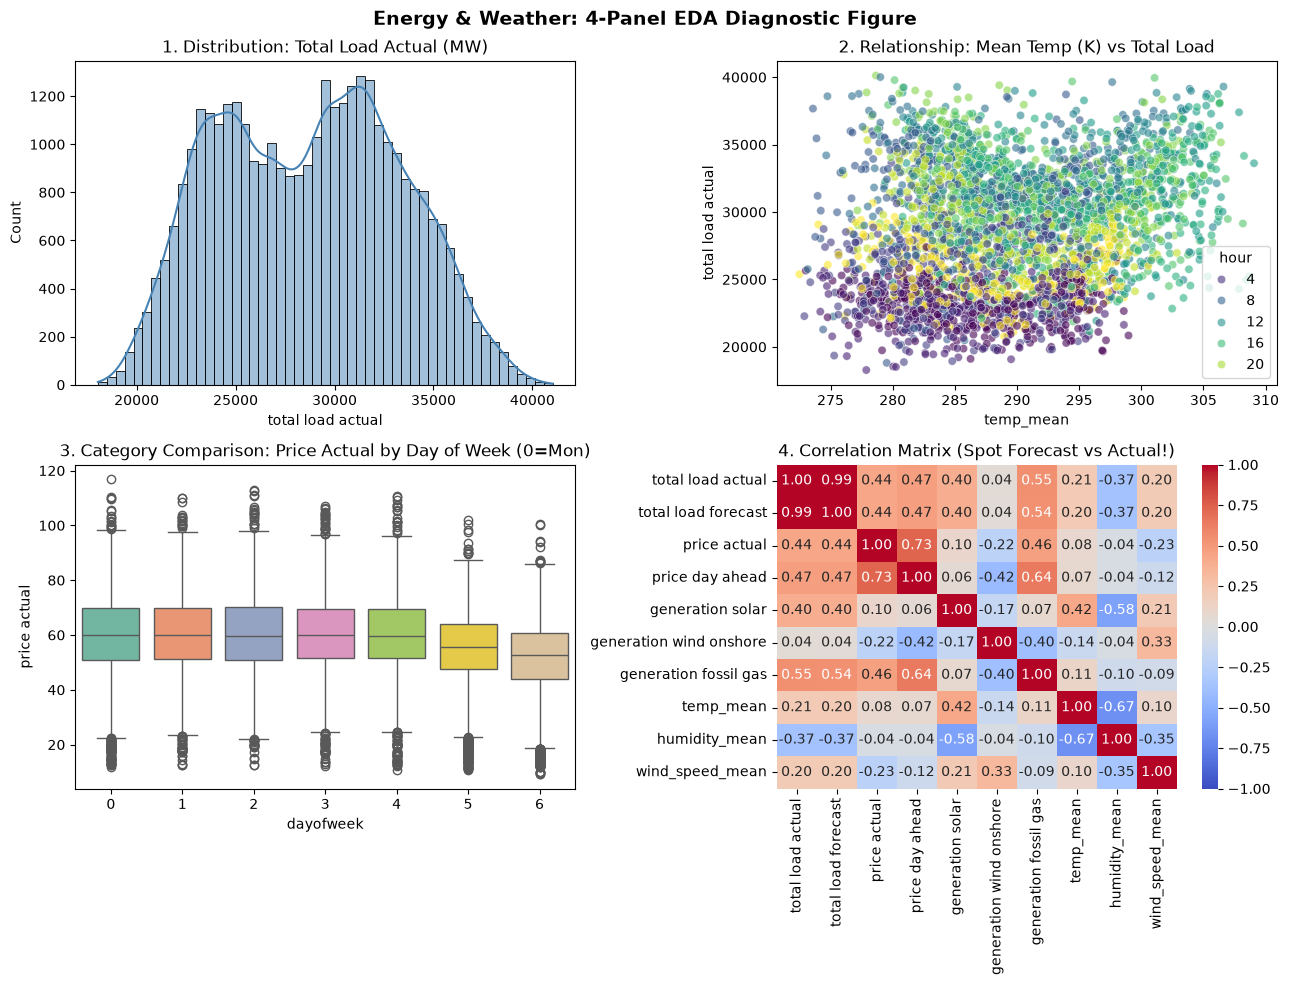

In [16]:
# Explicit fig, axes = plt.subplots(2, 2)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 1. Distribution (histplot): Total Load Actual
sns.histplot(data=merged, x='total load actual', kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('1. Distribution: Total Load Actual (MW)')

# 2. Relationship (scatterplot): Temperature vs Total Load (sampled for readability)
sample_df = merged.iloc[::10]
sns.scatterplot(data=sample_df, x='temp_mean', y='total load actual', hue='hour', palette='viridis', alpha=0.6, ax=axes[0, 1])
axes[0, 1].set_title('2. Relationship: Mean Temp (K) vs Total Load')

# 3. Category Comparison (boxplot): Electricity Price across Day of Week
sns.boxplot(data=merged, x='dayofweek', y='price actual', hue='dayofweek', legend=False, ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('3. Category Comparison: Price Actual by Day of Week (0=Mon)')

# 4. Correlation Matrix (heatmap): Key features vs targets
corr_cols = [
    'total load actual', 'total load forecast',
    'price actual', 'price day ahead',
    'generation solar', 'generation wind onshore', 'generation fossil gas',
    'temp_mean', 'humidity_mean', 'wind_speed_mean'
]
sns.heatmap(
    merged[corr_cols].corr(),
    annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm', ax=axes[1, 1]
)
axes[1, 1].set_title('4. Correlation Matrix (Spot Forecast vs Actual!)')

fig.suptitle('Energy & Weather: 4-Panel EDA Diagnostic Figure', fontsize=14, fontweight='bold')
fig.tight_layout()
fig.savefig(cfg.plot_dir / 'eda_4panel.png', dpi=150)
plt.show()

## Step 5: Chronological Train / Val / Test Split, Parquet Storage & Float32 Standardization
1. **Chronological split (70% / 15% / 15%)** without shuffling so future rows never leak into past predictions.
2. **Save as Parquet (`.to_parquet()`)** instead of CSV so schema/dtypes (`datetime64`) survive and column projection (`columns=[...]`) is fast.
3. **Standardize using ONLY `train` statistics (`mu`, `sd`)** via NumPy broadcasting `(X - mu) / sd`.
4. **Convert to `float32` at the boundary** (`np.ascontiguousarray(..., dtype=np.float32)`) for memory efficiency.

In [17]:
# 1. Chronological split (no random shuffle!)
n = len(merged)
train_end = int(n * cfg.train_ratio)
val_end = int(n * (cfg.train_ratio + cfg.val_ratio))

train_df = merged.iloc[:train_end]
val_df = merged.iloc[train_end:val_end]
test_df = merged.iloc[val_end:]

assert len(train_df) + len(val_df) + len(test_df) == n, "Split row counts do not sum to total!"
assert train_df['time'].max() < val_df['time'].min(), "Temporal leakage between train and val!"
assert val_df['time'].max() < test_df['time'].min(), "Temporal leakage between val and test!"

print(f"Train: {train_df.shape} | {train_df['time'].min()} -> {train_df['time'].max()}")
print(f"Val:   {val_df.shape} | {val_df['time'].min()} -> {val_df['time'].max()}")
print(f"Test:  {test_df.shape} | {test_df['time'].min()} -> {test_df['time'].max()}")

# 2. Save splits as Parquet (preserves datetime64 schema & compresses 2-3x smaller)
train_df.to_parquet(cfg.out_dir / 'train.parquet', index=False)
val_df.to_parquet(cfg.out_dir / 'val.parquet', index=False)
test_df.to_parquet(cfg.out_dir / 'test.parquet', index=False)

# Verify round-trip and projection pushdown (reading only selected columns)
feature_cols = ['temp_mean', 'pressure_mean', 'humidity_mean', 'wind_speed_mean', 'generation solar', 'generation wind onshore']
X_train_raw = pd.read_parquet(cfg.out_dir / 'train.parquet', columns=feature_cols).to_numpy()
X_val_raw = pd.read_parquet(cfg.out_dir / 'val.parquet', columns=feature_cols).to_numpy()
X_test_raw = pd.read_parquet(cfg.out_dir / 'test.parquet', columns=feature_cols).to_numpy()

# 3. Vectorized standardization using ONLY train mu and sd (no data leakage!)
mu = X_train_raw.mean(axis=0)  # shape (d,) -> one mean per feature
sd = X_train_raw.std(axis=0)   # shape (d,) -> one std per feature

X_train = np.ascontiguousarray((X_train_raw - mu) / sd, dtype=np.float32)
X_val = np.ascontiguousarray((X_val_raw - mu) / sd, dtype=np.float32)
X_test = np.ascontiguousarray((X_test_raw - mu) / sd, dtype=np.float32)

# Assert shape, dtype, zero NaNs, and unit standardization
assert X_train.dtype == np.float32, f"Expected float32, got {X_train.dtype}"
assert not np.isnan(X_train).any(), "NaN found in X_train!"
assert np.allclose(X_train.mean(axis=0), 0.0, atol=1e-5), "Train features not centered!"
assert np.allclose(X_train.std(axis=0), 1.0, atol=1e-5), "Train features not unit std!"
print('Standardized X_train:', X_train.shape, X_train.dtype)

Train: (24544, 32) | 2014-12-31 23:00:00+00:00 -> 2017-10-19 14:00:00+00:00
Val:   (5260, 32) | 2017-10-19 15:00:00+00:00 -> 2018-05-26 18:00:00+00:00
Test:  (5260, 32) | 2018-05-26 19:00:00+00:00 -> 2018-12-31 22:00:00+00:00
Standardized X_train: (24544, 6) float32
